In [9]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns

import os
pistack_dir = os.getcwd()
os.chdir('../')
from edautils.plot import ternary_ax, ternary
from edautils.plot import calc_portion, energy_bar_ax
from edautils.plot import kdeplot, kdeplot_norm
from edautils.plot import violin
from edautils.plot import pie
from edautils.plot import plot
os.chdir(pistack_dir)

plt.rcParams.update({
    # 'font.size': 12,
    # 'axes.titlesize': 12,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Lato'],
})

COLOR_MAPS = {
    "TOTAL": '#666666',
    "CT": '#b80058',
    "DISP": "#d95f02",
    "ELEC": '#5954d6',
    "POL": '#1b9e77',
    "PAULI": '#ebac23',
    'FRZ': '#a6cee3'
}

# Salt Bridge Statistics

In [71]:
df = pd.read_csv('salt_bridge_EDA.csv').iloc[:, 1:]
print('# Total pairs:', len(df))
print('# Repulsive pairs:', len(df.query('TOTAL > 0')))
print('# Attractive pairs:', len(df.query('TOTAL < 0')))

hbonds = pd.read_csv('../hbonds/hbond_EDA.csv').iloc[:, 1:]
hbonds = hbonds.query("(charge0 < 0 and charge1 > 0) or (charge0 > 0 and charge1 < 0)")
hbonds['protispos'] = hbonds['charge0'] < 0

print('# Total pairs:', len(hbonds))
print('# Repulsive pairs:', len(hbonds.query('TOTAL > 0')))
print('# Attractive pairs:', len(hbonds.query('TOTAL < 0')))

# CLS_DISP
df['DISP'] = np.where(np.isnan(df['DISP'].values), df['CLS_DISP'], df['DISP'])
hbonds['DISP'] = np.where(np.isnan(hbonds['DISP'].values), hbonds['CLS_DISP'], hbonds['DISP'])
processed_df = pd.concat([df, hbonds], axis=0)
processed_df = processed_df.query('TOTAL < 0').drop(columns=['resnr_lig', 'restype_lig', 'reschain_lig', 'PREPARATION'])

charge0 = set(processed_df['charge0'])
charge1 = set(processed_df['charge1'])
restype = set(processed_df['restype'])
lig_group = set(processed_df['lig_group'])
restype_lig_group = (processed_df.groupby('restype')['lig_group'].apply(set).to_dict())

print(f'charge ligand: {charge0}')
print(f'charge protein: {charge1}')
print(f'restypes: {restype}')
print(f'lig_groups: {lig_group}\n')
print(f'restype_ligand interaction pairs: {restype_lig_group}\n')

for x, subdf in processed_df.groupby("charge0"):
    print(x, subdf.shape[0], subdf['TOTAL'].mean())


# Total pairs: 1976
# Repulsive pairs: 5
# Attractive pairs: 1971
# Total pairs: 281
# Repulsive pairs: 0
# Attractive pairs: 281
charge ligand: {1.0, 2.0, -2.0, -5.0, -4.0, -3.0, -1.0}
charge protein: {1.0, -1.0}
restypes: {'GLU', 'SER', 'HIS', 'LYS', 'MET', 'ARG', 'PRO', 'ASP'}
lig_groups: {'Sulfonicacid', 'Sulfonium', nan, 'Tertamine', 'Sulfate', 'Phosphate', 'Carboxylate', 'Guanidine', 'Quartamine'}

restype_ligand interaction pairs: {'ARG': {'Sulfonicacid', nan, 'Phosphate', 'Sulfate', 'Carboxylate'}, 'ASP': {'Sulfonium', nan, 'Tertamine', 'Guanidine', 'Quartamine'}, 'GLU': {'Guanidine', nan, 'Tertamine', 'Quartamine'}, 'HIS': {'Carboxylate', nan, 'Phosphate'}, 'LYS': {'Sulfonicacid', nan, 'Sulfate', 'Phosphate', 'Carboxylate'}, 'MET': {nan}, 'PRO': {nan}, 'SER': {nan}}

-5.0 14 -1335.2671142857141
-4.0 105 -1247.7983114285714
-3.0 111 -987.3376090090092
-2.0 412 -711.4369468446602
-1.0 1009 -391.1177735381566
1.0 594 -395.6174616161616
2.0 7 -728.6221571428572


103    -2.0
370    -1.0
1047   -1.0
1221   -1.0
1651   -1.0
Name: charge0, dtype: float64


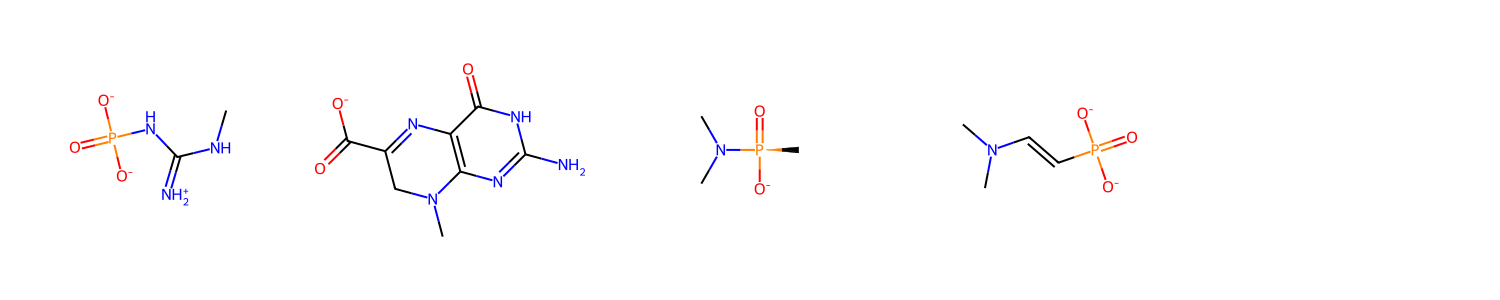

In [80]:
print(df.query("(charge0 <= 0 and protispos == False)")['charge0'])

from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df.query("(charge0 <= 0 and protispos == False)")['smiles0'])], subImgSize=(300, 300), molsPerRow=5)

In [105]:
def violin_float(axes, group_name, groups, labels, processed_df, plot='violin'):
    components = [
        ('TOTAL', 'TOTAL'),
        ('MOD_PAULI', 'PAULI'),
        ('CLS_ELEC', 'ELEC'),
        ('DISP', 'DISP'),
        ('POLARIZATION', 'POL'),
        ('CHARGE_TRANSFER', 'CT')
    ]
    
    for i, (c, label) in enumerate(components):
        ax = axes.flatten()[i]
        processed_df_all = processed_df.copy()

        if 'ALL' in groups:
            processed_df_all[group_name] = 'ALL' 
            processed_df_all = pd.concat([processed_df, processed_df_all])

        if plot == 'violin':

            if len(groups) == 2:
                xticks = [-0.22, 0.22]
            elif len(groups) == 3:
                xticks = [-0.3, 0.0, 0.3]
            elif len(groups) == 4:
                xticks = [-0.34, -0.11, 0.11, 0.34]
            elif len(groups) == 5:
                xticks = [-0.36, -0.18, 0.0, 0.18, 0.36]

            sns.violinplot(processed_df_all, hue=group_name, y=c, ax=ax, density_norm='width', cut=0, split=False, inner=None, legend=False, gap=0.1, width=0.9, hue_order=groups)
            ax.set_xticks(xticks)
            ax.set_xticklabels(labels)
        elif plot == 'bar':

            if len(groups) == 2:
                xticks = [0, 1]
            elif len(groups) == 3:
                xticks = [0, 1, 2]
            elif len(groups) == 4:
                xticks = [0, 1, 2, 3]
            elif len(groups) == 5:
                xticks = [0, 1, 2, 3, 4]

            for n, group in enumerate(groups):
                subdf = processed_df_all.query(f"{group_name} == {group}")
                data = subdf[c]
                err = np.abs(np.percentile(data, 75) - np.percentile(data, 25)) / 2
                ax.bar(n, np.median(data), yerr=err, color=COLOR_MAPS[label], alpha=0.9, width=0.5, capsize=3, error_kw={'elinewidth': 1.5})
            ax.set_xticks(xticks)
            ax.set_xticklabels(labels)
        
        ax.set_title(label)
        for index in range(len(ax.collections)):
            ax.collections[index].set_facecolor(COLOR_MAPS[label])
            ax.collections[index].set_alpha(1.0 - (0.13 * index))
        ax.set_axisbelow(True)
        ax.grid(True, axis='y', which='both')
        ax.set_ylabel('')
        ax.tick_params(direction='in', which='both', axis='y')

    return axes


def pie_float(axes, group_name, groups, labels, processed_df, type='TOTAL'):
    def compute_fraction(df):
        pol = np.mean(df['POLARIZATION'])
        ct = np.mean(df['CHARGE_TRANSFER'])
        elec = np.mean(df['CLS_ELEC'])
        pauli = np.mean(df['MOD_PAULI'])
        disp = np.mean(df['DISP'])
        tot = np.mean(df['TOTAL'])

        orb = pol + ct
        stab = orb + elec + disp
        frz = elec + disp + pauli
        if type == 'TOTAL':
            return [frz/tot, pol/tot, ct/tot]
        elif type == 'STABILIZING':
            return [elec/stab, disp/stab, pol/stab, ct/stab]

    def find_label(x, data):
        if type == 'TOTAL':
            pcts = [data[0]/sum(data)*100, data[1]/sum(data)*100, data[2]/sum(data)*100]
            if abs(pcts[0] - x) < 1e-5:
                return f'FRZ\n({x:.2f}%)'
            elif abs(pcts[1] - x) < 1e-5:
                return f'POL\n({x:.2f}%)'
            elif abs(pcts[2] - x) < 1e-5:
                return f'CT\n({x:.2f}%)'
            else:
                return f'{x:.2f}%'
        elif type == 'STABILIZING':
            pcts = [data[0]/sum(data)*100, data[1]/sum(data)*100, data[2]/sum(data)*100, data[3]/sum(data)*100]
            if abs(pcts[0] - x) < 1e-5:
                return f'ELEC\n({x:.2f}%)'
            elif abs(pcts[1] - x) < 1e-5:
                return f'DISP\n({x:.2f}%)'
            elif abs(pcts[2] - x) < 1e-5:
                return f'POL\n({x:.2f}%)'
            elif abs(pcts[3] - x) < 1e-5:
                return f'CT\n({x:.2f}%)'
            else:
                return f'{x:.2f}%'
    
    if type == 'TOTAL':
        kwargs = dict(
            colors=[COLOR_MAPS['FRZ'], COLOR_MAPS['POL'], COLOR_MAPS['CT']], 
            textprops=dict(fontsize=12),
            wedgeprops = {'linewidth': 3, 'clip_on': True},
            autopct=lambda p: find_label(p, data)
        )
    elif type == 'STABILIZING':
        kwargs = dict(
            colors=[COLOR_MAPS['ELEC'], COLOR_MAPS['DISP'], COLOR_MAPS['POL'], COLOR_MAPS['CT']], 
            textprops=dict(fontsize=12),
            wedgeprops = {'linewidth': 3, 'clip_on': True},
            autopct=lambda p: find_label(p, data)
        )

    processed_df_all = processed_df.copy()
    if 'ALL' in groups:
        processed_df_all[group_name] = 'ALL' 
        processed_df_all = pd.concat([processed_df, processed_df_all])

    if group_name is None:
        data = compute_fraction(processed_df_all)
        axes.pie(data, **kwargs)
        axes.set_title(labels[0], fontsize=14)
        axes.set_aspect('equal')
    elif len(groups) > 1:
        for i in range(len(groups)):
            data = compute_fraction(processed_df_all.query(f"{group_name} == {groups[i]}"))
            axes[i].pie(data, **kwargs)
            axes[i].set_title(labels[i], fontsize=14)
            axes[i].set_xlim(-1, 1)
            axes[i].set_ylim(-1.1, 1.1)
    elif len(groups) == 1:
        data = compute_fraction(processed_df_all.query(f"{group_name} == '{groups[0]}'"))
        axes.pie(data, **kwargs)
        axes.set_title(labels[0], fontsize=14)
        axes.set_aspect('equal')

    return axes

# Total Interactions

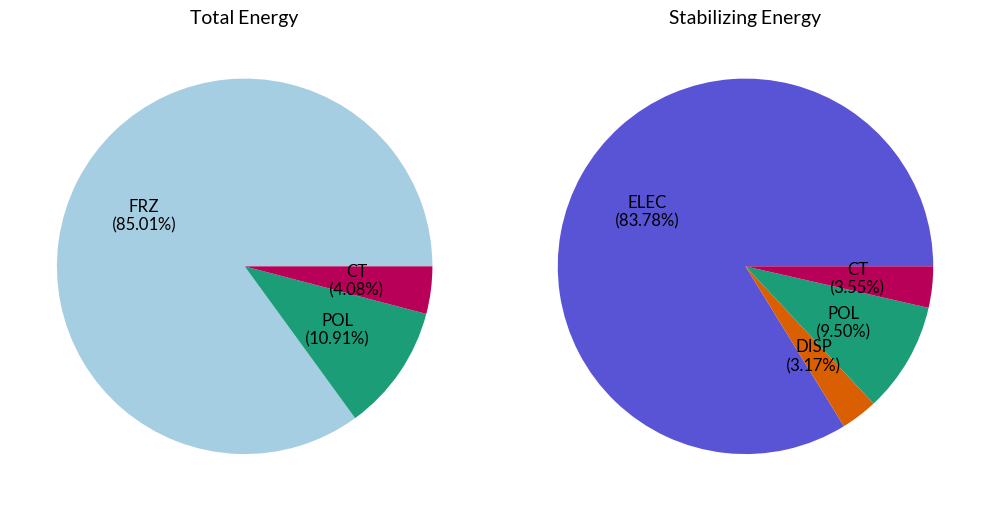

In [113]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

fig, axes = plt.subplots(1, 2, constrained_layout=True, figsize=(10, 5))

pie_float(axes[0], None, ['ALL'], ['Total Energy'],  processed_df, type='TOTAL')
pie_float(axes[1], None, ['ALL'], ['Stabilizing Energy'], processed_df, type='STABILIZING')
plt.savefig('Visualizations/pie.pdf')

# Hbonds Seperate Analysis

In [54]:
processed_hbonds.columns

Index(['full_PDBID', 'subdir', 'resnr', 'restype', 'reschain', 'sidechain',
       'dist_h-a', 'dist_d-a', 'don_angle', 'protisdon', 'donoridx',
       'donortype', 'acceptoridx', 'acceptortype', 'ligcoo_x', 'ligcoo_y',
       'ligcoo_z', 'protcoo_x', 'protcoo_y', 'protcoo_z', 'natoms0', 'charge0',
       'smiles0', 'natoms1', 'charge1', 'smiles1', 'elements', 'xyz', 'ELEC',
       'PAULI', 'DISP', 'CLS_ELEC', 'MOD_PAULI', 'CLS_DISP', 'FROZEN',
       'POLARIZATION', 'CHARGE_TRANSFER', 'TOTAL', 'protispos'],
      dtype='object')

In [62]:
# for x, subdf in processed_hbonds.groupby("donortype"):
#     print(x, subdf.shape[0], subdf['TOTAL'].min())

# for x, subdf in processed_hbonds.groupby("acceptortype"):
#     print(x, subdf.shape[0], subdf['TOTAL'].min())

for x, subdf in processed_hbonds.groupby("charge0"):
    print(x, subdf.shape[0], subdf['TOTAL'].min())

-4.0 7 -1514.6779
-3.0 7 -1186.0993
-2.0 55 -993.3436
-1.0 73 -511.0848
1.0 137 -562.4779
2.0 2 -666.0959


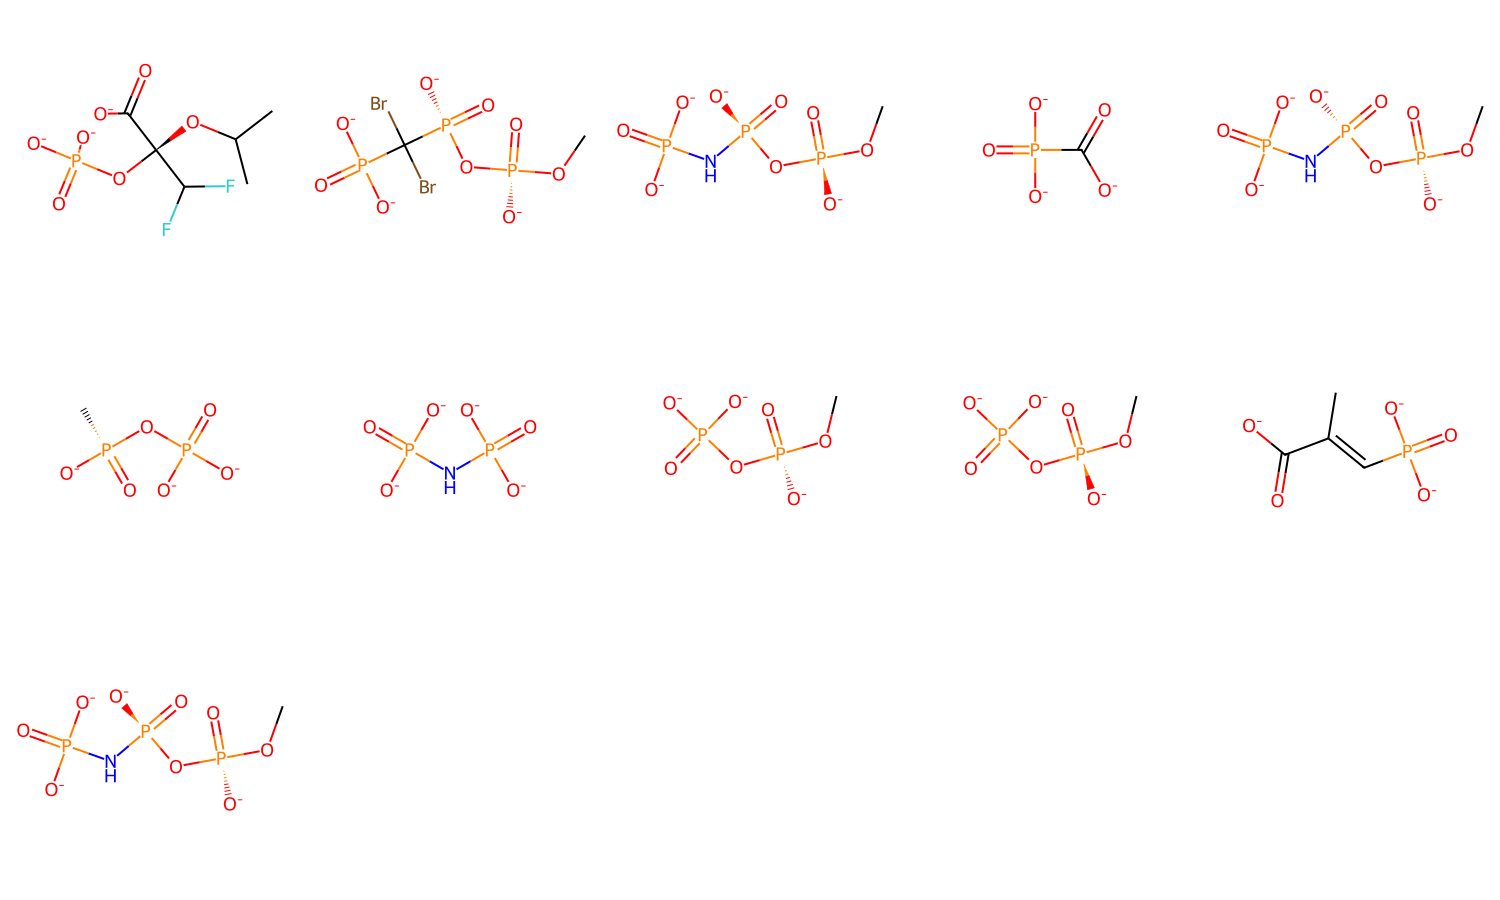

In [68]:
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(processed_hbonds.query("charge0 < -2.0")['smiles0'])], subImgSize=(300, 300), molsPerRow=5)

False 139 -666.0959
True 142 -1514.6779
142
139


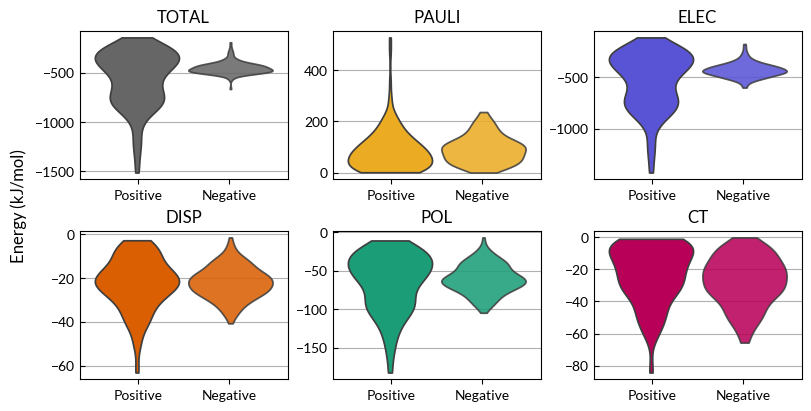

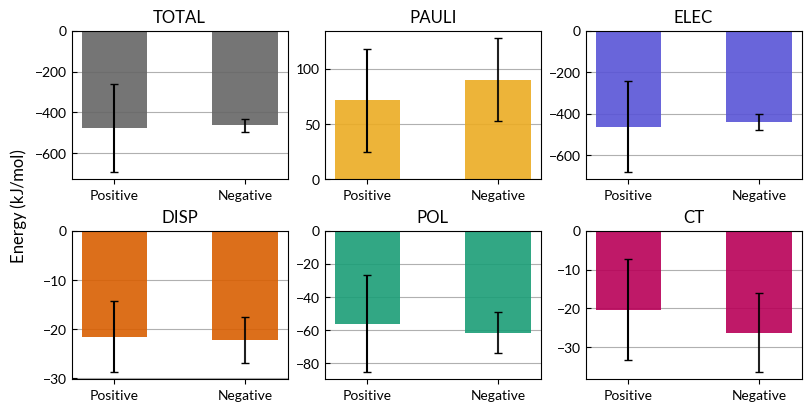

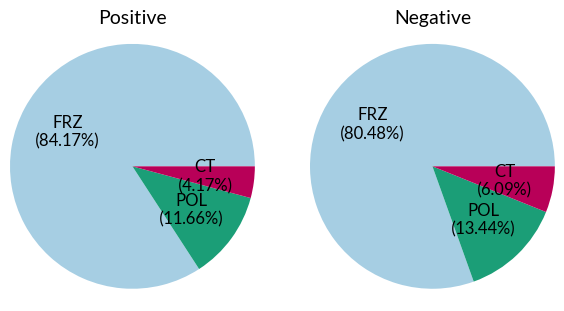

In [83]:
processed_hbonds = hbonds.query('TOTAL < 0').drop(columns=['resnr_lig', 'restype_lig', 'reschain_lig', 'PREPARATION'])

for x, subdf in processed_hbonds.groupby("protispos"):
    print(x, subdf.shape[0], subdf['TOTAL'].min())

from matplotlib import font_manager
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

group_name = 'protispos'
groups = [True, False]
labels = ['Positive', 'Negative']

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin_float(axes, group_name, groups, labels, processed_hbonds, plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin_hbonds.png')

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin_float(axes, group_name, groups, labels, processed_hbonds, plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar_hbonds.png')

fig, axes = plt.subplots(1, 2, constrained_layout=True, figsize=(6, 3))
pie_float(axes, group_name, groups, labels, processed_hbonds)
fig.savefig('Visualizations/pie_hbonds.png')

# Protispos

In [81]:
for x, subdf in processed_df.groupby("protispos"):
    print(x, subdf.shape[0], subdf['TOTAL'].mean())

components = [
    ('TOTAL', 'TOTAL', 'Total'),
    ('MOD_PAULI', 'PAULI', 'Pauli'),
    ('CLS_ELEC', 'CLS_ELEC', 'Electrostatics'),
    ('DISP', 'DISP', 'Dispersion'),
    ('POLARIZATION', 'POL', 'Polarization'),
    ('CHARGE_TRANSFER', 'CT', 'Charge Transfer')
]

include_all = True
for c, label, pp in components:
    line = f'{pp}'
    if include_all:
        line += f'${np.mean(processed_df[c]):.2f}\\ ({np.median(processed_df[c]):.2f})$'
    for x in [True, False]:
        data = processed_df.query(f'protispos == {x}')[c]
        line += f' & ${np.mean(data):.2f}\\ ({np.median(data):.2f})$'
    line += ' \\\\'
    print(line)

False 601 -399.4960520798669
True 1651 -573.6262219866748
Total$-527.16\ (-444.28)$ & $-573.63\ (-462.20)$ & $-399.50\ (-406.97)$ \\
Pauli$78.30\ (66.02)$ & $80.27\ (67.74)$ & $72.91\ (60.04)$ \\
Electrostatics$-507.24\ (-432.55)$ & $-550.81\ (-453.64)$ & $-387.56\ (-387.69)$ \\
Dispersion$-19.20\ (-18.67)$ & $-19.57\ (-18.65)$ & $-18.17\ (-18.71)$ \\
Polarization$-57.53\ (-54.54)$ & $-61.46\ (-56.07)$ & $-46.73\ (-46.29)$ \\
Charge Transfer$-21.49\ (-18.85)$ & $-22.05\ (-19.39)$ & $-19.95\ (-15.67)$ \\


1509
462


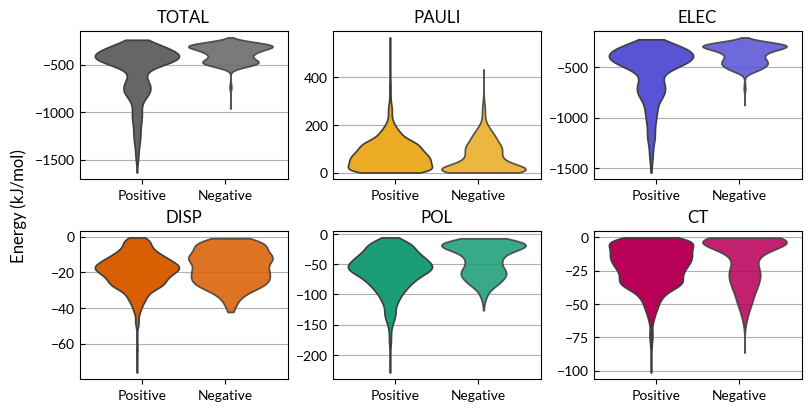

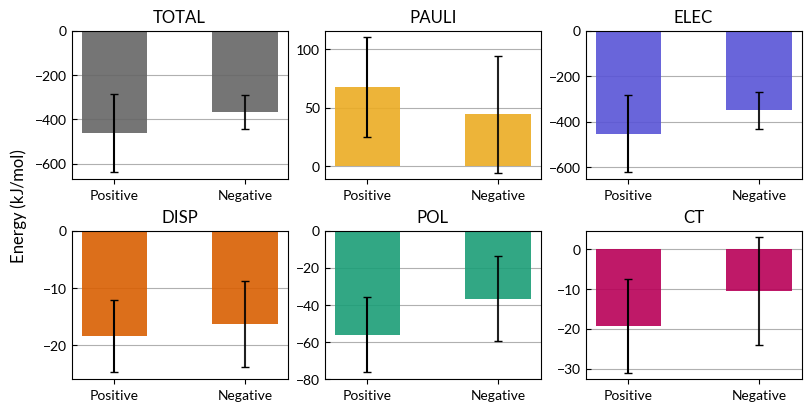

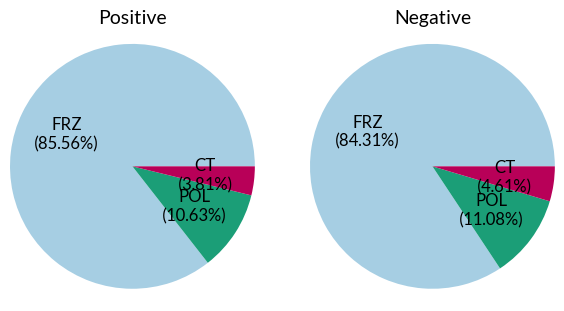

In [38]:
from matplotlib import font_manager
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

group_name = 'protispos'
groups = [True, False]
labels = ['Positive', 'Negative']

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin_float(axes, group_name, groups, labels, processed_df, plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin_protispos.png')

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin_float(axes, group_name, groups, labels, processed_df, plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar_protispos.png')

fig, axes = plt.subplots(1, 2, constrained_layout=True, figsize=(6, 3))
pie_float(axes, group_name, groups, labels, processed_df)
fig.savefig('Visualizations/pie_protispos.png')

# Oxyanions

In [17]:
processed_df["oxy_group"] = pd.NA

carboxyl_mask = (
    ((processed_df["restype"] == 'ASP') | (processed_df["restype"] == 'GLU')) |
    (processed_df["lig_group"] == 'Carboxylate')
)
phosphate_mask = (
    processed_df["lig_group"] == 'Phosphate'
)
sulfate_mask = (
    (processed_df["lig_group"] == 'Sulfate') | (processed_df["lig_group"] == 'Sulfonicacid')
)

processed_df.loc[carboxyl_mask, "oxy_group"] = "Carboxylate"
processed_df.loc[phosphate_mask, "oxy_group"] = "Phosphate"
processed_df.loc[sulfate_mask, "oxy_group"] = "Sulfate"

for x, subdf in processed_df.groupby("oxy_group"):
    print(x, subdf.shape[0], subdf['TOTAL'].mean(), set(subdf['charge0'].to_list()))



Carboxylate 1311 -400.162585583524 {1.0, 2.0, -2.0, -3.0, -1.0}
Phosphate 589 -839.4889001697793 {-1.0, -5.0, -4.0, -3.0, -2.0}
Sulfate 71 -364.16597464788737 {-1.0, -2.0}


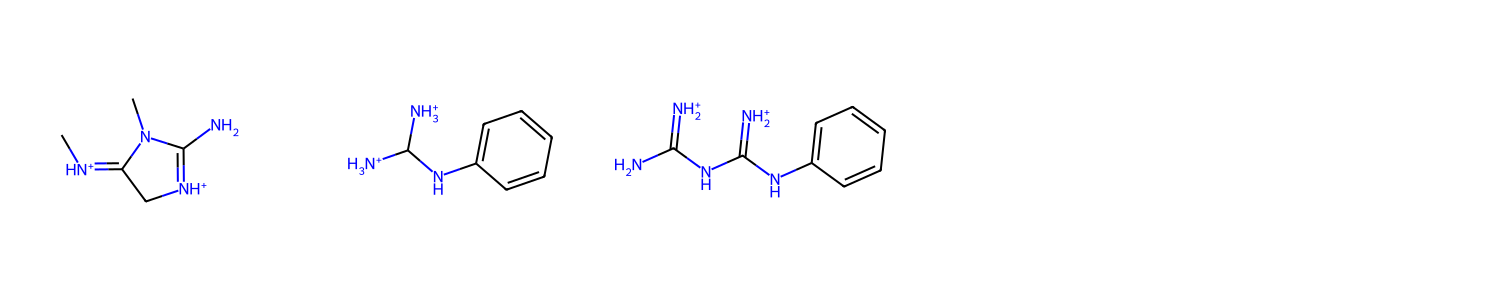

In [21]:
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(processed_df.query("charge0 == 2.0")['smiles0'])], subImgSize=(300, 300), molsPerRow=5)

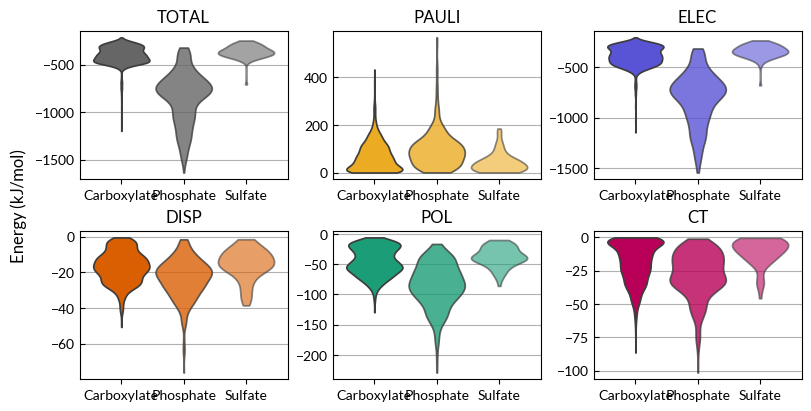

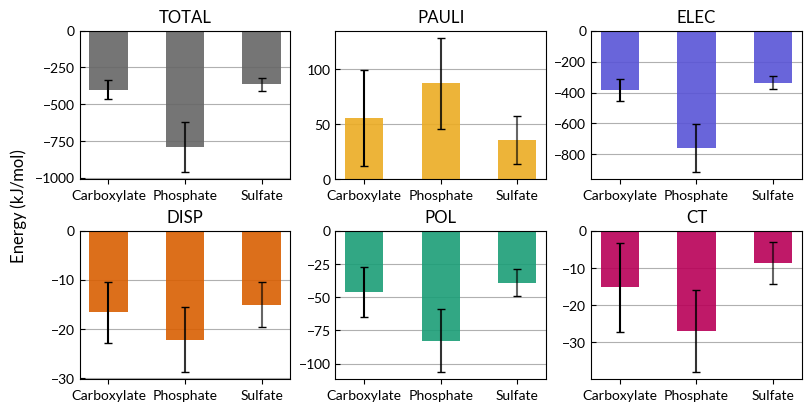

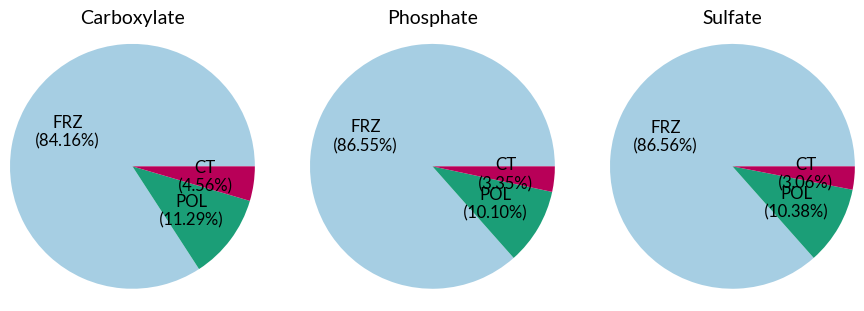

In [22]:
from matplotlib import font_manager
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

group_name = 'oxy_group'
groups = ['Carboxylate', 'Phosphate', 'Sulfate']
labels = ['Carboxylate', 'Phosphate', 'Sulfate']

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin_oxy.png')

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin(axes, group_name, groups, labels, processed_df, plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar_oxy.png')

fig, axes = plt.subplots(1, 3, constrained_layout=True, figsize=(9, 3))
pie(axes, group_name, groups, labels, processed_df)
fig.savefig('Visualizations/pie_oxy.png')

# Ion types

In [24]:
print('positive nitrogen protein: ')
print(len(processed_df.query("restype == 'HIS'"))) # positive nitrogen
print(len(processed_df.query("restype == 'ARG'")))
print(len(processed_df.query("restype == 'LYS'")))

print('\nnegative oxygen protein: ')
print(len(processed_df.query("restype == 'ASP'"))) # negative oxygen
print(len(processed_df.query("restype == 'GLU'")))


print('\nnegative oxygen ligand: ')
print(len(processed_df.query("lig_group == 'Sulfate'"))) # negative oxygen
print(len(processed_df.query("lig_group == 'Sulfonicacid'")))
print(len(processed_df.query("lig_group == 'Phosphate'")))
print(len(processed_df.query("lig_group == 'Carboxylate'")))

print('\npositive nitrogen ligand: ')
print(len(processed_df.query("lig_group == 'Tertamine'"))) # positive nitrogen
print(len(processed_df.query("lig_group == 'Quartamine'")))

print('\npositive sulfur ligand: ')
print(len(processed_df.query("lig_group == 'Sulfonium'"))) # positive sulfur

positive nitrogen protein: 
15
818
676

negative oxygen protein: 
303
159

negative oxygen ligand: 
17
54
589
849

positive nitrogen ligand: 
231
14

positive sulfur ligand: 
10


# Different Charge Phosphate Group

In [25]:
print('\ncharge0 subdf phosphate count:')
for x, subdf in processed_df.groupby("charge0"):
    print(x, len(subdf.query("lig_group == 'Phosphate'")), subdf.query("lig_group == 'Phosphate'")['TOTAL'].mean())

print(processed_df.query("charge0 == -3.0 & lig_group != 'Phosphate'")['lig_group'].to_list())


charge0 subdf phosphate count:
-5.0 14 -1335.2671142857141
-4.0 98 -1243.3650285714284
-3.0 99 -991.4325343434342
-2.0 333 -715.9595057057057
-1.0 45 -385.53585555555554
1.0 0 nan
2.0 0 nan
['Carboxylate', 'Carboxylate', 'Carboxylate', 'Carboxylate', 'Carboxylate']


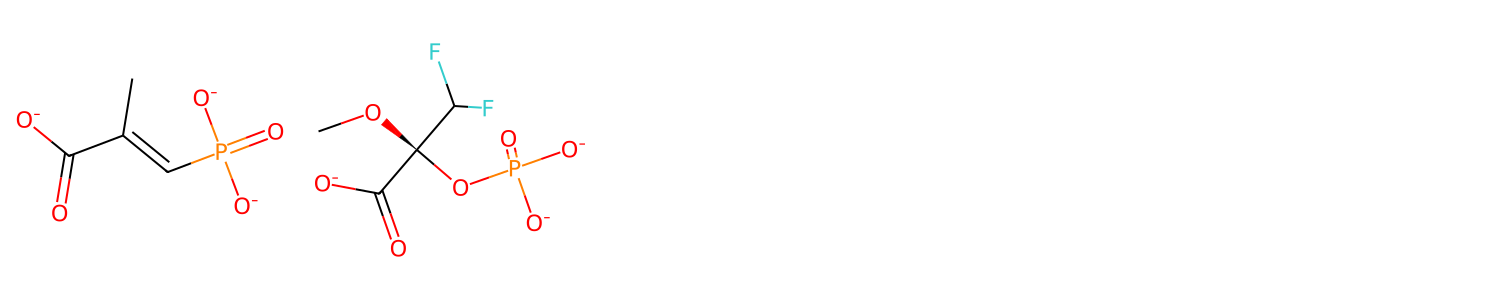

In [26]:
from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')


Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(processed_df.query("charge0 == -3.0 & lig_group != 'Phosphate'")['smiles0'])], subImgSize=(300, 300), molsPerRow=5)
# Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(processed_df.query("charge0 == -3.0")['smiles0'])], subImgSize=(300, 300), molsPerRow=5)
# Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df_4_lig['smiles0'])], subImgSize=(300, 300), molsPerRow=5)
# Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(df_5_lig['smiles0'])], subImgSize=(300, 300), molsPerRow=5)


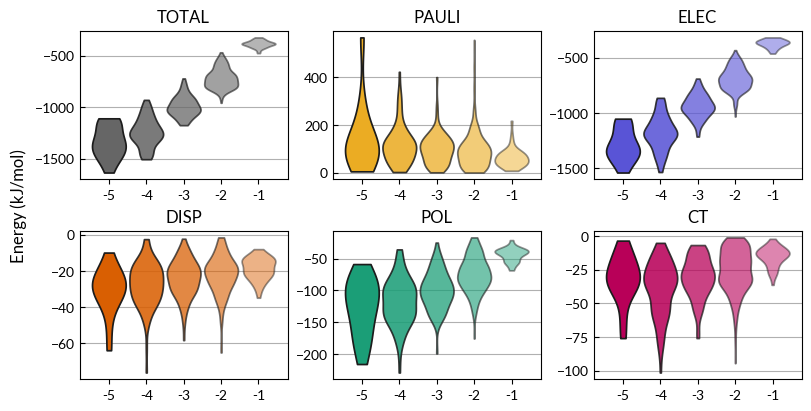

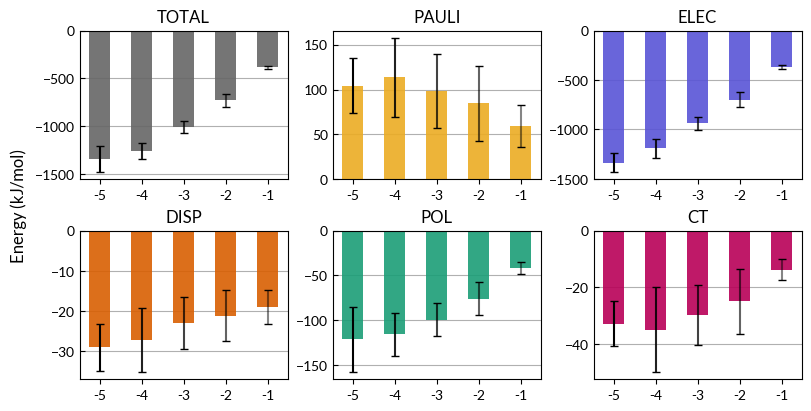

In [27]:
from matplotlib import font_manager
font_manager.fontManager.addfont("../edautils/fonts/Lato/Lato-Regular.ttf")
font_manager.fontManager.addfont("../edautils/fonts/Helvetica/Helvetica.ttf")

group_name = 'charge0'
# groups = [-1.0, -2.0, -3.0, -4.0, -5.0]
# labels = ['-1', '-2', '-3', '-4', '-5']
groups = [-5.0, -4.0, -3.0, -2.0, -1.0]
labels = ['-5', '-4', '-3', '-2', '-1']

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin_float(axes, group_name, groups, labels, processed_df.query("lig_group == 'Phosphate'"), plot='violin')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/violin_phos.png')

fig, axes = plt.subplots(2, 3, figsize=(8, 4), constrained_layout=True)
violin_float(axes, group_name, groups, labels, processed_df.query("lig_group == 'Phosphate'"), plot='bar')
fig.supylabel("Energy (kJ/mol)")
fig.savefig('Visualizations/bar_phos.png')